

---


**Project Title: Predicting Malignant vs. Benign Breast Tumors from Cell Nuclei Features**


---



In [ ]:
# Name, Id: Samin Safwan (23301388), Naim Mahmud peyas (22301646), Waess Karnee (23301454)
# Group: 10
# Section: CSE437 Section: 10

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/CSE437 Project/Breast Cancer Wisconsin (Diagnostic) Data Set.csv')

print(df.shape)
df.head()

(569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
df['diagnosis'].value_counts()

,count
diagnosis,
B,357
M,212


**Data Cleaning**


---



In [ ]:
# Dropping the empty column and the id column since id isn't a predictive feature

df = df.drop(columns=['Unnamed: 32', 'id'])

# Shape after dropping
print(df.shape)
df.head()

(569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
# Encoding my target variable: Malignant = 1, Benign = 0

df['diagnosis'] = df['diagnosis'].map({'M' : 1, 'B' : 0})

In [ ]:
# Checking for missing values and duplicate rows to confirm my data is clean

print("Missing values: ", df.isnull().sum().sum())
print("Duplicate rows: ", df.duplicated().sum())
print(df['diagnosis'].value_counts())

Missing values:  0
Duplicate rows:  0
diagnosis
0    357
1    212
Name: count, dtype: int64


Data cleaning done: no missing values, no duplicates, target encoded correctly (0=Benign: 357, 1=Malignant: 212).


In [ ]:
# Getting descriptive statistics for all my features

df.describe().T

,count,mean,std,min,25%,50%,75%,max
diagnosis,569.0,0.372583,0.483918,0.000000,0.000000,0.000000,1.000000,1.00000
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400


Observations:

1. Huge scale differences: Area_mean ranges up to 2501 while smoothness_mean maxes out at 0.16. If I fed this straight into a distance-based model or PCA without scaling, area would completely dominate just because of its numbers, not because it's more important. This is why we'll standardize before PCA.

2. Likely outliers/skew: For several features (e.g. area_mean: 75th percentile is 782 but max is 2501; radius_se: 75th is 0.48 but max is 2.87), the max is far beyond the 75th percentile. That's expected in medical data (some tumors are genuinely extreme cases). I'll visualize this in EDA rather than remove anything, since these aren't data errors.

**EDA**


---


 Visualizing Distributions and Relationships

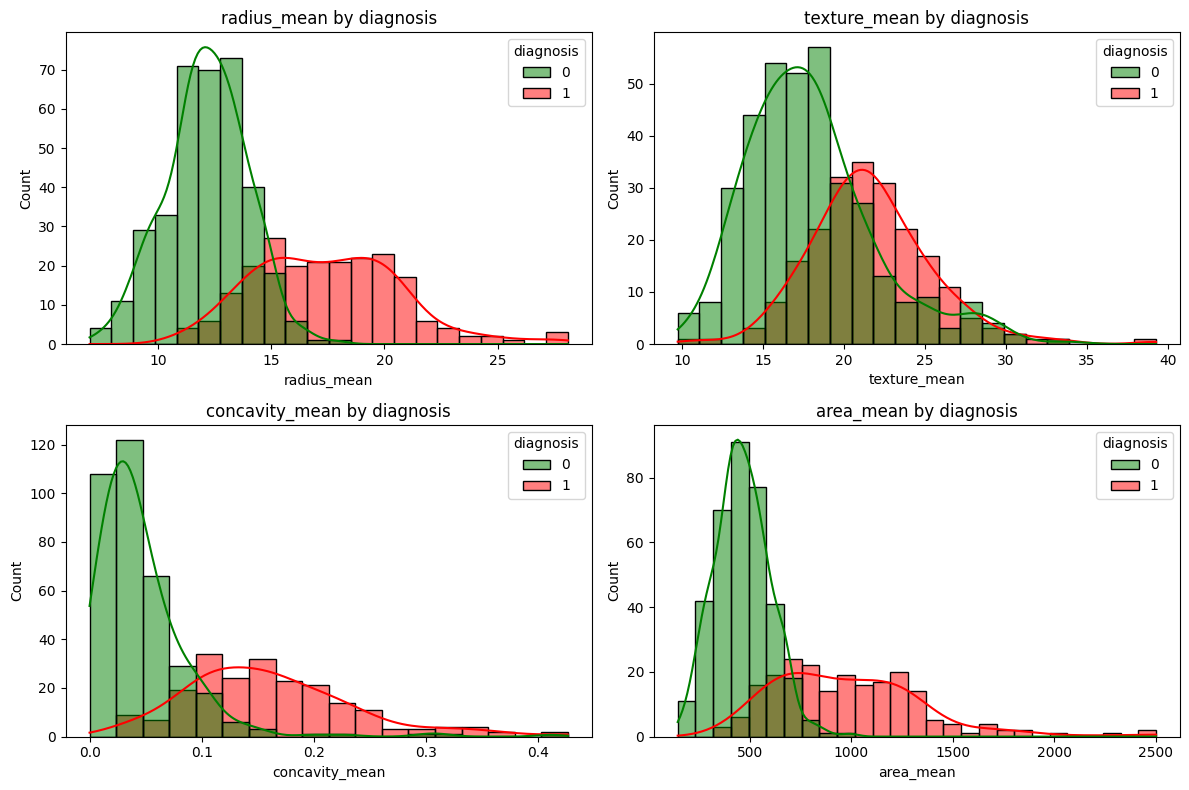

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Looking at how a few key features differ between benign and malignant tumors
features_to_plot = ['radius_mean', 'texture_mean', 'concavity_mean', 'area_mean']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, col in enumerate(features_to_plot):
    sns.histplot(data=df, x=col, hue='diagnosis', kde=True, ax=axes[i], palette=['green', 'red'])
    axes[i].set_title(f'{col} by diagnosis')

plt.tight_layout()
plt.show()

/tmp/ipykernel_11124/112565705.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='diagnosis', y='radius_mean', palette=['green', 'red'])


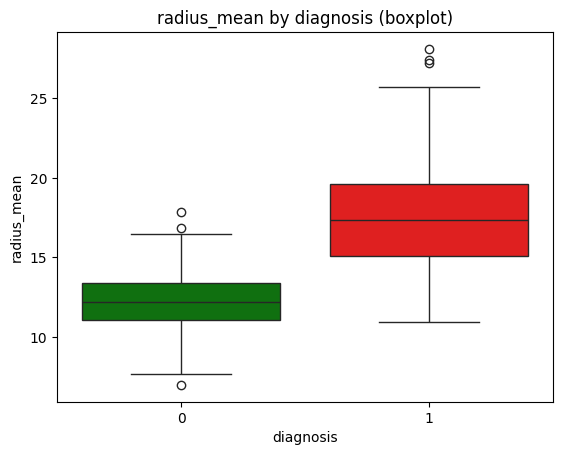

In [ ]:
# Making a boxplot to check for outliers in radius_mean, grouped by diagnosis
sns.boxplot(data=df, x='diagnosis', y='radius_mean', palette=['green', 'red'])
plt.title('radius_mean by diagnosis (boxplot)')
plt.show()

/tmp/ipykernel_11124/2769238121.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='diagnosis', y='area_mean', palette=['green', 'red'])


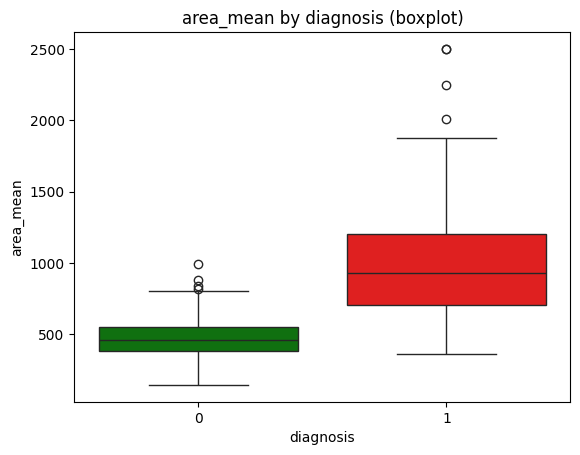

In [ ]:
# Making a boxplot to check for outliers in area_mean, grouped by diagnosis
sns.boxplot(data=df, x='diagnosis', y='area_mean', palette=['green', 'red'])
plt.title('area_mean by diagnosis (boxplot)')
plt.show()

Observations



*   Clear separation: In both plots, the malignant (red) box sits clearly higher than the benign (green) box, with barely any overlap between the boxes themselves. Visually confirming again that these two features strongly distinguish the classes.
*  Malignant group is more spread out: The red box is taller (wider range between 25th–75th percentile) than green in both cases, meaning malignant tumors vary more in size. This makes biological sense, since tumors can grow unpredictably once malignant.



*   Outliers (the little circles): A few benign cases have unusually large area_mean/radius_mean (above the whiskers), and malignant has a few extreme outliers too (like those 3 points near 2500 in area_mean). These are likely real unusual cases, not data errors.





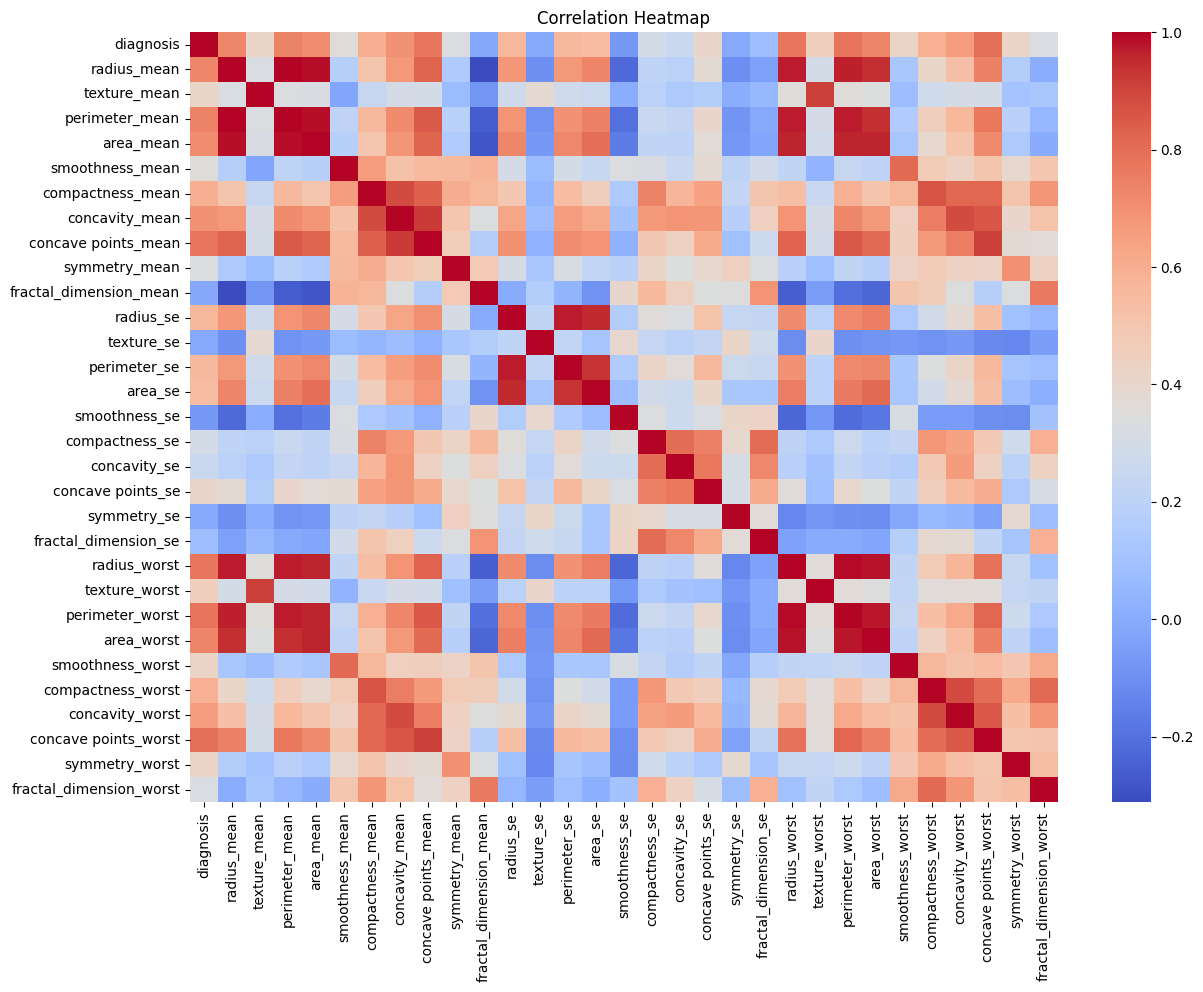

In [ ]:
# Making a correlation heatmap to see how features relate to each other
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

Observations:

*   radius_mean, perimeter_mean, area_mean are all deep red with each other (correlation near 1.0). This makes sense, since a bigger radius directly means a bigger perimeter and area. They're basically measuring the same underlying thing (tumor size) in three different ways.
*   Same pattern repeats for the _se group and the _worst group. The radius/perimeter/area are tightly linked in all three versions.

*   concavity, concave points, and compactness also cluster together (moderately-to-strongly correlated). These all relate to how irregular/jagged the cell boundary is.
*   smoothness and fractal_dimension are much less correlated with the others. They capture something more independent.


*   Looking at the diagnosis row/column: radius, perimeter, area, concavity, and concave points all show a fairly strong positive correlation with diagnosis. This is consistent with what was seen in the histograms.







**Statistical testing**

---


Using a t-test to mathematically confirm which features differ significantly between malignant and benign groups (backing up what the heatmap and histograms suggested).


In [ ]:
from scipy import stats

# Splitting the data into two groups: benign and malignant
benign = df[df['diagnosis'] == 0]
malignant = df[df['diagnosis'] == 1]

# Running a t-test on radius_mean to see if the difference between groups is significant
t_stat, p_value = stats.ttest_ind(benign['radius_mean'], malignant['radius_mean'])
print("t-statistic:", t_stat)
print("p-value:", p_value)

t-statistic: -25.435821610057054
p-value: 8.465940572262422e-96


In [ ]:
# Running the same t-test for texture_mean
t_stat, p_value = stats.ttest_ind(benign['texture_mean'], malignant['texture_mean'])
print("texture_mean -> t-statistic:", t_stat, " p-value:", p_value)

texture_mean -> t-statistic: -10.86720108146434  p-value: 4.058636047898074e-25


In [ ]:
# Running the same t-test for concavity_mean
t_stat, p_value = stats.ttest_ind(benign['concavity_mean'], malignant['concavity_mean'])
print("concavity_mean -> t-statistic:", t_stat, " p-value:", p_value)

concavity_mean -> t-statistic: -23.103963430622642  p-value: 9.966555755072963e-84


In [ ]:
# Running the same t-test for area_mean
t_stat, p_value = stats.ttest_ind(benign['area_mean'], malignant['area_mean'])
print("area_mean -> t-statistic:", t_stat, " p-value:", p_value)

area_mean -> t-statistic: -23.938687235690992  p-value: 4.734564310307344e-88


**Conclusion**: All four are statistically significant (p-values nowhere close to 0.05). But exactly as predicted, texture_mean has the "weakest" significance (p ≈ 4x10^-25) compared to radius_mean, concavity_mean, and area_mean (all around 10^-84 to 10^-96). This lines up perfectly with the extra overlap seen in its histogram earlier. Texture still matters, but it separates the two groups less cleanly than the others.

**Scaling the features and running PCA**


---



In [ ]:
# Importing tools for scaling and PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Separating my features from the target
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# Scaling my features so they're all on the same scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

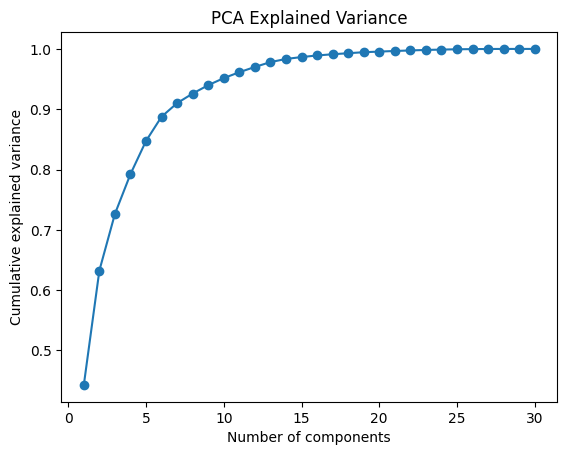

In [ ]:
# Running PCA to see how many components are needed to explain most of the variance
pca = PCA()
pca.fit(X_scaled)

# Plotting cumulative explained variance
plt.plot(range(1, len(pca.explained_variance_ratio_)+1), pca.explained_variance_ratio_.cumsum(), marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA Explained Variance')
plt.show()

In [ ]:
# Finding exactly how many components are needed to reach 95% variance
import numpy as np

cumulative_variance = pca.explained_variance_ratio_.cumsum()
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print("Number of components needed for 95% variance:", n_components_95)

Number of components needed for 95% variance: 10


In [ ]:
# Reducing my data down to 10 components that capture 95% of the variance
pca_final = PCA(n_components=10)
X_pca = pca_final.fit_transform(X_scaled)

print(X_pca.shape)

(569, 10)


Splitting the data into Training and Testing Sets


In [ ]:
# Splitting my data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(455, 10) (114, 10)


Model: Logistic Regression

In [ ]:
# Training a logistic regression model
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression()
log_model.fit(X_train, y_train)

log_preds = log_model.predict(X_test)

Model: Decision Tree

In [ ]:
# Training a decision tree model
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)

tree_preds = tree_model.predict(X_test)

Model: Random Forest

In [ ]:
# Training a random forest model
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(random_state=42)
forest_model.fit(X_train, y_train)

forest_preds = forest_model.predict(X_test)

Accuracy of Each Model

In [ ]:
# Checking accuracy for each model
from sklearn.metrics import accuracy_score, classification_report

print("Logistic Regression accuracy:", accuracy_score(y_test, log_preds))
print("Decision Tree accuracy:", accuracy_score(y_test, tree_preds))
print("Random Forest accuracy:", accuracy_score(y_test, forest_preds))

Logistic Regression accuracy: 0.9824561403508771
Decision Tree accuracy: 0.9210526315789473
Random Forest accuracy: 0.9385964912280702


Classification Report for Logistic Regression

In [ ]:
# Getting a detailed classification report for logistic regression
print(classification_report(y_test, log_preds))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        72
           1       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



Confusion Matrix for Logistic Regression

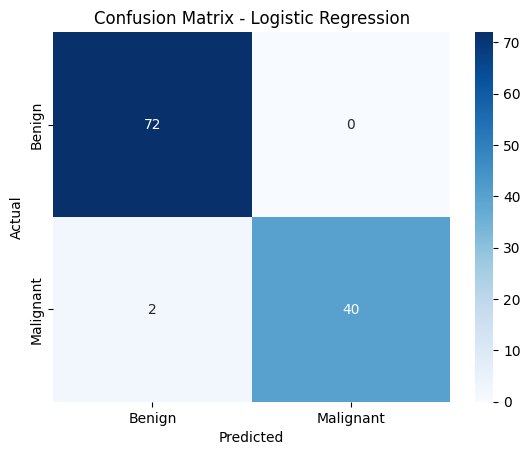

In [ ]:
# Getting the confusion matrix for logistic regression
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, log_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Benign','Malignant'], yticklabels=['Benign','Malignant'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()